## Who Worked On This Part?
Muhammad Azaam Ali: trained and tuned the random forest, and looked at which features it uses.

# Mushroom: random forest

PyCaret ranked the **random forest** clearly first (cross-validated AUC 0.83, against 0.70 for logistic regression). In this notebook we build it ourselves, tune it, and look at which features it relies on.

**How a random forest works:** it trains hundreds of decision trees, each on a random sample of the rows (drawn with replacement) and with a random subset of the features at every split. Every tree makes different mistakes; the forest averages their votes. One tree on its own learns the noise in the data (PyCaret: a single tree only got AUC 0.67), but averaging many different trees cancels most of that noise out. That's why it suits this dataset with its flipped labels.

## Load the split
Same train and validation files as `3MushroomPredict.ipynb` and `3.1MushroomPyCaret.ipynb`, so all models are compared on exactly the same rows. The test file stays untouched until the compare notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# walk up from where the notebook runs to the repo root, so the data path works on every machine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Mushroom' / 'datasets').is_dir())
DATA = ROOT / 'Mushroom' / 'datasets'

train_df = pd.read_csv(DATA / 'train.csv')
val_df = pd.read_csv(DATA / 'val.csv')

X_train, y_train = train_df.drop(columns='is_poisonous'), train_df['is_poisonous']
X_val, y_val = val_df.drop(columns='is_poisonous'), val_df['is_poisonous']

num_cols = ['cap_diameter_cm', 'stem_height_cm', 'stem_width_mm']
cat_cols = [c for c in X_train.columns if c not in num_cols]

X_train.shape, X_val.shape

((3500, 10), (750, 10))

## How we score a model
The same `evaluate()` as in `3MushroomPredict.ipynb`, so the numbers can be compared directly: ROC-AUC (ranking, no threshold), and recall / precision / F1 / accuracy at threshold 0.5.

In [2]:
from sklearn.metrics import roc_auc_score, recall_score, precision_score, f1_score, accuracy_score

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, proba),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred, zero_division=0),
        'f1': f1_score(y_true, pred),
        'accuracy': accuracy_score(y_true, pred),
    }

## The pipeline
Trees are simpler to prepare than logistic regression:
- **categorical columns**: still one-hot encoded, because sklearn trees only work with numbers
- **numeric columns**: passed through unchanged (`remainder='passthrough'`). A tree only asks questions like *"is stem width above 12 mm?"*, so the scale doesn't matter and `log1p` or `StandardScaler` would change nothing: they keep the order of the values, and the order is all a split looks at.

We start with the default settings and 300 trees. `n_jobs=-1` uses all CPU cores, `random_state=42` makes the random choices repeatable.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

prep = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)], remainder='passthrough')

rf = Pipeline([
    ('prep', prep),
    ('rf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
])
rf.fit(X_train, y_train)

pd.DataFrame({
    'rf default (train)': evaluate(y_train, rf.predict_proba(X_train)[:, 1]),
    'rf default (val)': evaluate(y_val, rf.predict_proba(X_val)[:, 1]),
}).T.round(3)

,roc_auc,recall,precision,f1,accuracy
rf default (train),1.000,1.000,1.000,1.000,1.000
rf default (val),0.848,0.644,0.813,0.719,0.809


### What this tells us
On the training data the forest is perfect (every score 1.0), on validation the AUC is 0.85. With the default settings every tree grows until each leaf holds a single mushroom, so every tree has **memorised** its training rows, including the mislabelled ones. That's overfitting at the level of a single tree.

But the forest is not useless because of it: what counts is the validation score, and that is far better than logistic regression (AUC 0.85 vs 0.70, recall 0.64 vs 0.39 at threshold 0.5). Every tree memorises *different* rows (each saw a different random sample), so their mistakes point in different directions and largely cancel out when the 300 votes are averaged. A big gap between train and validation is normal for a random forest; the validation score is what we judge it on.

## Tuning
Three settings control how much each tree can memorise:
- `max_depth`: how many questions deep a tree may go (`None` = until the leaves are pure)
- `min_samples_leaf`: the minimum number of mushrooms in a leaf. Bigger leaves = less memorising of single (possibly mislabelled) rows
- `max_features`: how many features each split may choose from. `'sqrt'` ≈ 8 of the 64 one-hot columns, `0.3` = 30% of them. Fewer = more different trees

`GridSearchCV` tries **every combination**: 3 × 4 × 2 = 24 combinations, each with 5-fold cross-validation on the training data = 120 forests. It keeps the best by AUC. Validation is not used for choosing.

In [4]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    rf,
    param_grid={
        'rf__max_depth': [None, 10, 20],
        'rf__min_samples_leaf': [1, 3, 5, 10],
        'rf__max_features': ['sqrt', 0.3],
    },
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
)
grid.fit(X_train, y_train)

# the 8 best combinations, with the spread over the 5 folds
results = pd.DataFrame(grid.cv_results_)
results.sort_values('rank_test_score')[['param_rf__max_depth', 'param_rf__min_samples_leaf', 'param_rf__max_features', 'mean_test_score', 'std_test_score']].head(8).round(3)

,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__max_features,mean_test_score,std_test_score
4,None,1,0.3,0.832,0.016
0,None,1,sqrt,0.831,0.014
20,20,1,0.3,0.830,0.016
16,20,1,sqrt,0.830,0.013
5,None,3,0.3,0.829,0.018
1,None,3,sqrt,0.825,0.013
21,20,3,0.3,0.825,0.017
6,None,5,0.3,0.822,0.015


In [5]:
rf_tuned = grid.best_estimator_
print('best settings:', grid.best_params_)

pd.DataFrame({
    'rf default (val)': evaluate(y_val, rf.predict_proba(X_val)[:, 1]),
    'rf tuned (train)': evaluate(y_train, rf_tuned.predict_proba(X_train)[:, 1]),
    'rf tuned (val)': evaluate(y_val, rf_tuned.predict_proba(X_val)[:, 1]),
}).T.round(3)

best settings: {'rf__max_depth': None, 'rf__max_features': 0.3, 'rf__min_samples_leaf': 1}


,roc_auc,recall,precision,f1,accuracy
rf default (val),0.848,0.644,0.813,0.719,0.809
rf tuned (train),1.000,1.000,1.000,1.000,1.000
rf tuned (val),0.852,0.620,0.822,0.707,0.805


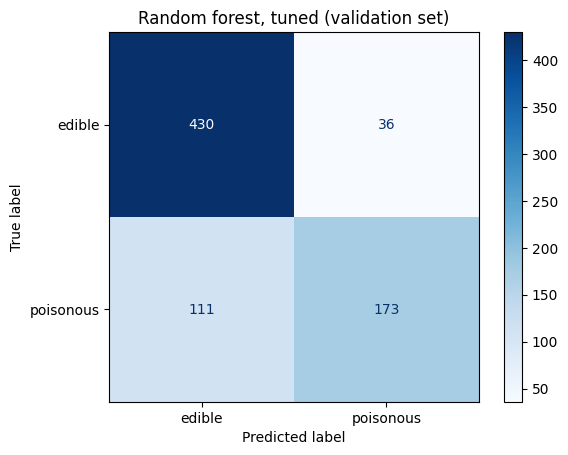

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_val, rf_tuned.predict(X_val), display_labels=['edible', 'poisonous'], cmap='Blues')
plt.title('Random forest, tuned (validation set)')
plt.show()

### What this tells us
The best combinations are very close together: the top 4 all score 0.830 to 0.832, while the score varies about 0.015 between folds. So the differences between them are noise. The best one (`max_features=0.3`, no depth limit, `min_samples_leaf=1`) is practically the default forest, and on validation it gains only 0.004 AUC (0.848 → 0.852). The default forest was already about as good as it gets; tuning confirmed that rather than improved it.

What the grid does show: bigger leaves and a depth limit make the forest slightly **worse**, so stopping the trees from memorising doesn't help here; the averaging already takes care of that.

At threshold 0.5 the tuned forest still calls 108 of the 284 poisonous validation mushrooms edible. That's fewer than logistic regression (173, or 113 when balanced), and it also wrongly flags far fewer edible mushrooms (38 against 145 for balanced logistic regression). The remaining misses are what the threshold in the compare notebook is for.

## Which features does the forest use?
**Permutation importance:** take the validation set, shuffle one column so its values no longer belong to the right mushroom, and measure how much the AUC drops. A big drop means the model really relies on that column; no drop means it could do without it.

We do this on the **original 10 columns** (not the 64 one-hot columns), because the pipeline takes the raw columns as input. `n_repeats=10` shuffles every column 10 times and averages, because one shuffle can be lucky.

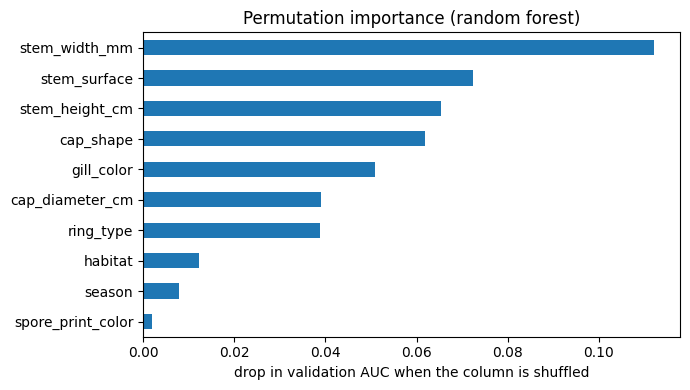

In [7]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf_tuned, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()

importance.plot.barh(figsize=(7, 4))
plt.xlabel('drop in validation AUC when the column is shuffled')
plt.title('Permutation importance (random forest)')
plt.tight_layout()
plt.show()

### What this tells us
The forest relies most on the **stem**: stem width (AUC drops 0.11 when shuffled), stem surface (0.07) and stem height (0.07), then cap shape (0.06) and gill color (0.05). This matches the EDA: stem surface, cap shape and ring type had the strongest link with the class, and the measurements differed between edible and poisonous. The measurements weigh even more here than in the EDA, because a tree can combine them with each other and with the categories.

Habitat and season matter little, and **spore_print_color** hardly at all (0.002): with 95% of it missing, the forest finds almost nothing in it that the other columns don't already tell it. Keeping it doesn't hurt the forest; the drop we measured in the cleaning notebook when removing spore_print_color *together with* stem_surface came mostly from losing stem_surface, which is the second most important column here.

## Save the model
The whole pipeline (one-hot encoding + model) goes to `models/random_forest.pkl`, next to `logreg.pkl`. The compare notebook loads all saved models and scores them on the same data. GitHub refuses files over 100 MB, so we print the size.

In [8]:
import joblib

MODELS = ROOT / 'Mushroom' / 'models'
MODELS.mkdir(exist_ok=True)
joblib.dump(rf_tuned, MODELS / 'random_forest.pkl', compress=3)  # compress: a forest of hundreds of trees is big otherwise
print(round((MODELS / 'random_forest.pkl').stat().st_size / 1e6, 1), 'MB')

6.1 MB


## Conclusion
The random forest is the best model so far. The default forest already gets validation AUC 0.848; tuning with GridSearchCV (24 combinations, 5-fold cross-validation) gives 0.852, a difference within the noise between folds. Compared to logistic regression (0.70) it is much better, because it can learn combinations of features, and averaging 300 different trees cancels most of the label noise that a single tree would memorise.

What still goes wrong: at threshold 0.5 it misses 108 of the 284 poisonous validation mushrooms. We fix the threshold in the compare notebook. The prediction is carried mostly by the stem (width, surface, height), cap shape and gill color; spore_print_color adds almost nothing.

Note for deployment: `model/train.py` uses `min_samples_leaf=3` for the hosted forest. Our grid found 1 slightly better (0.832 vs 0.829), but that difference is within the noise, so both are fine.